---
title: Week 6 Challenge 3 Heatmaps and Color (KEY)
subtitle: DS 2023 | Communicating with Data
---

## Overview

In today's challenge, you will apply what you have learned about heatmaps and color.

Use the notebooks **Heatmaps** and **Color** as your guide.

Work in groups to perform the tasks.

When finished, submit a URL to this notebook in your GitHub repo to today's participation assignment.

## The data set

Today's dataset comes from the **Smithsonian Institution's Global Volcanism Program** and records $1{,}328$ volcanoes that have been active during the Holocene (the last ~11,700 years).

Each row is one volcano.

**Selected columns**

| Variable | Data Type | Description |
|---|---|---|
| Volcano_Name | String | Name of the volcano. |
| Region | Categorical (19 levels) | World region where the volcano is located. |
| Primary_Volcano_Type | Categorical | Type of volcano (32 raw categories; we simplify to 6 below). |
| Elevation | Integer | Summit elevation in meters; negative values are submarine. |
| Evidence_Category | Categorical | Strength of evidence for Holocene activity. |
| Tectonic_Setting | Categorical | Tectonic environment (subduction zone, rift zone, intraplate). |

In the Set Up we simplify `Primary_Volcano_Type` to a `Type` column with six values: Stratovolcano, Shield, Volcanic field, Submarine, Caldera, and Other.

## Set Up

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
DATA_URL = (
    "https://gist.githubusercontent.com/mattkram/9684863843254402942dfede27af2cb7"
    "/raw/2590dd8185b833aacf247c0595edbb07a025a6d7"
    "/Smithsonian_VOTW_Holocene_Volcanoes.csv"
)

volcanoes = pd.read_csv(DATA_URL)

# Simplify the 32 raw volcano types to five named types plus Other
volcanoes['Type'] = (
    volcanoes['Primary_Volcano_Type']
    .astype(str)
    .str.replace(r'\(.*\)', '', regex=True)
    .str.strip()
)
top5 = volcanoes['Type'].value_counts().head(5).index
volcanoes['Type'] = volcanoes['Type'].where(volcanoes['Type'].isin(top5), 'Other')

volcanoes.info()
volcanoes.head()

<class 'pandas.DataFrame'>
RangeIndex: 1328 entries, 0 to 1327
Data columns (total 21 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   FID                    1328 non-null   str    
 1   Volcano_Number         1328 non-null   int64  
 2   Volcano_Name           1328 non-null   str    
 3   Primary_Volcano_Type   1328 non-null   str    
 4   Last_Eruption_Year     859 non-null    float64
 5   Country                1328 non-null   str    
 6   Geological_Summary     1328 non-null   str    
 7   Region                 1328 non-null   str    
 8   Subregion              1328 non-null   str    
 9   Latitude               1328 non-null   float64
 10  Longitude              1328 non-null   float64
 11  Elevation              1328 non-null   int64  
 12  Tectonic_Setting       1323 non-null   str    
 13  Geologic_Epoch         1328 non-null   str    
 14  Evidence_Category      1327 non-null   str    
 15  Primary_Photo_L

,FID,Volcano_Number,Volcano_Name,Primary_Volcano_Type,Last_Eruption_Year,Country,Geological_Summary,Region,Subregion,Latitude,...,Elevation,Tectonic_Setting,Geologic_Epoch,Evidence_Category,Primary_Photo_Link,Primary_Photo_Caption,Primary_Photo_Credit,Major_Rock_Type,GeoLocation,Type
0,Smithsonian_VOTW_Holocene_Volcanoes.fid--d9082...,210010,West Eifel Volcanic Field,Volcanic field,-8300.0,Germany,The West Eifel Volcanic Field of western Germa...,Mediterranean and Western Asia,Western Europe,50.170,...,600,Rift zone / Continental crust (> 25 km),Holocene,Eruption Dated,https://volcano.si.edu/gallery/photos/GVP-0150...,The lake-filled Weinfelder maar is one of abou...,"Photo by Richard Waitt, 1990 (U.S. Geological ...",Foidite,POINT (50.17 6.85),Volcanic field
1,Smithsonian_VOTW_Holocene_Volcanoes.fid--d9082...,210020,Chaine des Puys,Lava dome(s),-4040.0,France,"The Chaîne des Puys, prominent in the history ...",Mediterranean and Western Asia,Western Europe,45.775,...,1464,Rift zone / Continental crust (> 25 km),Holocene,Eruption Dated,https://volcano.si.edu/gallery/photos/GVP-0880...,The central part of the Chaîne des Puys volcan...,Photo by Ichio Moriya (Kanazawa University).,Basalt / Picro-Basalt,POINT (45.775 2.97),Other
2,Smithsonian_VOTW_Holocene_Volcanoes.fid--d9082...,210030,Olot Volcanic Field,Volcanic field,NaN,Spain,The Olot volcanic field (also known as the Gar...,Mediterranean and Western Asia,Western Europe,42.170,...,893,Intraplate / Continental crust (> 25 km),Holocene,Evidence Credible,https://volcano.si.edu/gallery/photos/GVP-1199...,The forested Volcà Montolivet scoria cone rise...,Photo by Puigalder (Wikimedia Commons).,Trachybasalt / Tephrite Basanite,POINT (42.17 2.53),Volcanic field
3,Smithsonian_VOTW_Holocene_Volcanoes.fid--d9082...,210040,Calatrava Volcanic Field,Volcanic field,-3600.0,Spain,The Calatrava volcanic field lies in central S...,Mediterranean and Western Asia,Western Europe,38.870,...,1117,Intraplate / Continental crust (> 25 km),Holocene,Eruption Dated,https://volcano.si.edu/gallery/photos/GVP-1185...,"Columba volcano, the youngest known vent of th...","Photo by Rafael Becerra Ramírez, 2006 (Univers...",Basalt / Picro-Basalt,POINT (38.87 -4.02),Volcanic field
4,Smithsonian_VOTW_Holocene_Volcanoes.fid--d9082...,211004,Colli Albani,Caldera,NaN,Italy,The Colli Albani (Alban Hills) complex immedia...,Mediterranean and Western Asia,Italy,41.730,...,949,Subduction zone / Continental crust (> 25 km),Holocene,Evidence Uncertain,https://volcano.si.edu/gallery/photos/GVP-0881...,The lake-filled Albano maar is part of the Alb...,Photo by Ichio Moriya (Kanazawa University).,Foidite,POINT (41.73 12.7),Caldera


## Tasks

### Task 1

Use `pd.pivot_table()` to create a matrix of **volcano counts** with `Region` as rows and `Type` as columns.

Pass `aggfunc='count'`, `values='Volcano_Number'`, and `fill_value=0`.

Store the result as `counts`, then call `sns.heatmap()` on it with `cmap='YlOrRd'`.

Which region has the most stratovolcanoes?

Which type is rarest overall, and where does it concentrate?

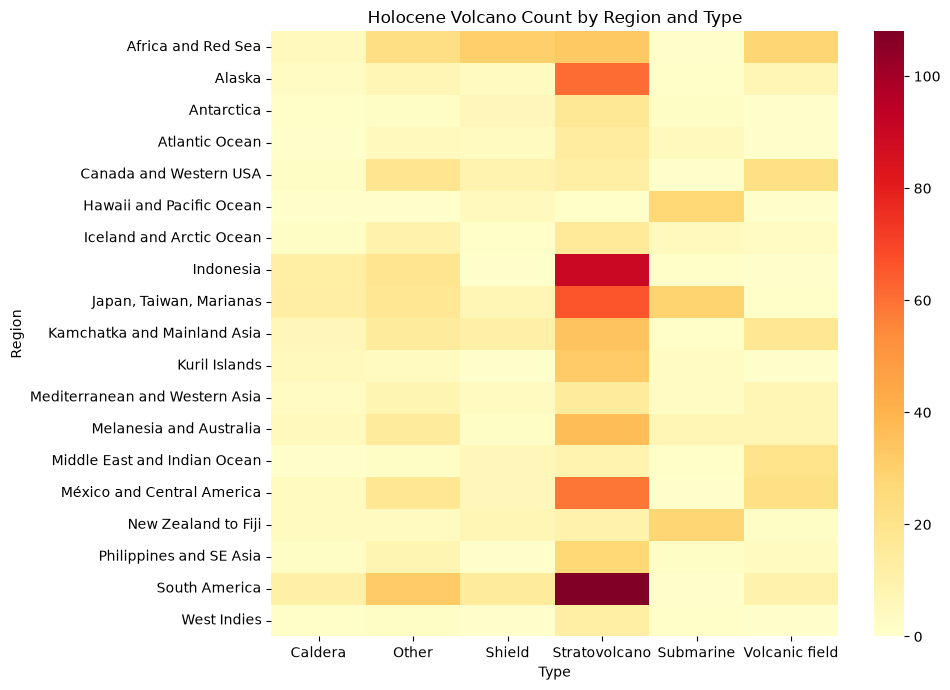

In [3]:
counts = pd.pivot_table(
    volcanoes, index='Region', columns='Type',
    values='Volcano_Number', aggfunc='count', fill_value=0
)

plt.figure(figsize=(10, 7))
sns.heatmap(counts, cmap='YlOrRd')
plt.title('Holocene Volcano Count by Region and Type')
plt.tight_layout()
plt.show()

**Answers**:

- **South America** has the most stratovolcanoes — its cell is the brightest in that column by a wide margin (~140).

- **Caldera** is the rarest named type overall.

- **Submarine** volcanoes, while sparse across most regions, concentrate heavily in Hawaii and the Pacific Ocean and in Japan/Taiwan/Marianas

  - These are the **Pacific Ring of Fire's most ocean-dominated arcs**.

### Task 2

Redraw the `counts` heatmap three times side by side, each with a different colormap: `'viridis'`, `'Blues'`, and `'rocket_r'`.

What does the `_r` suffix do to a colormap?

Which of the three colormaps makes the structure easiest to read, and why?

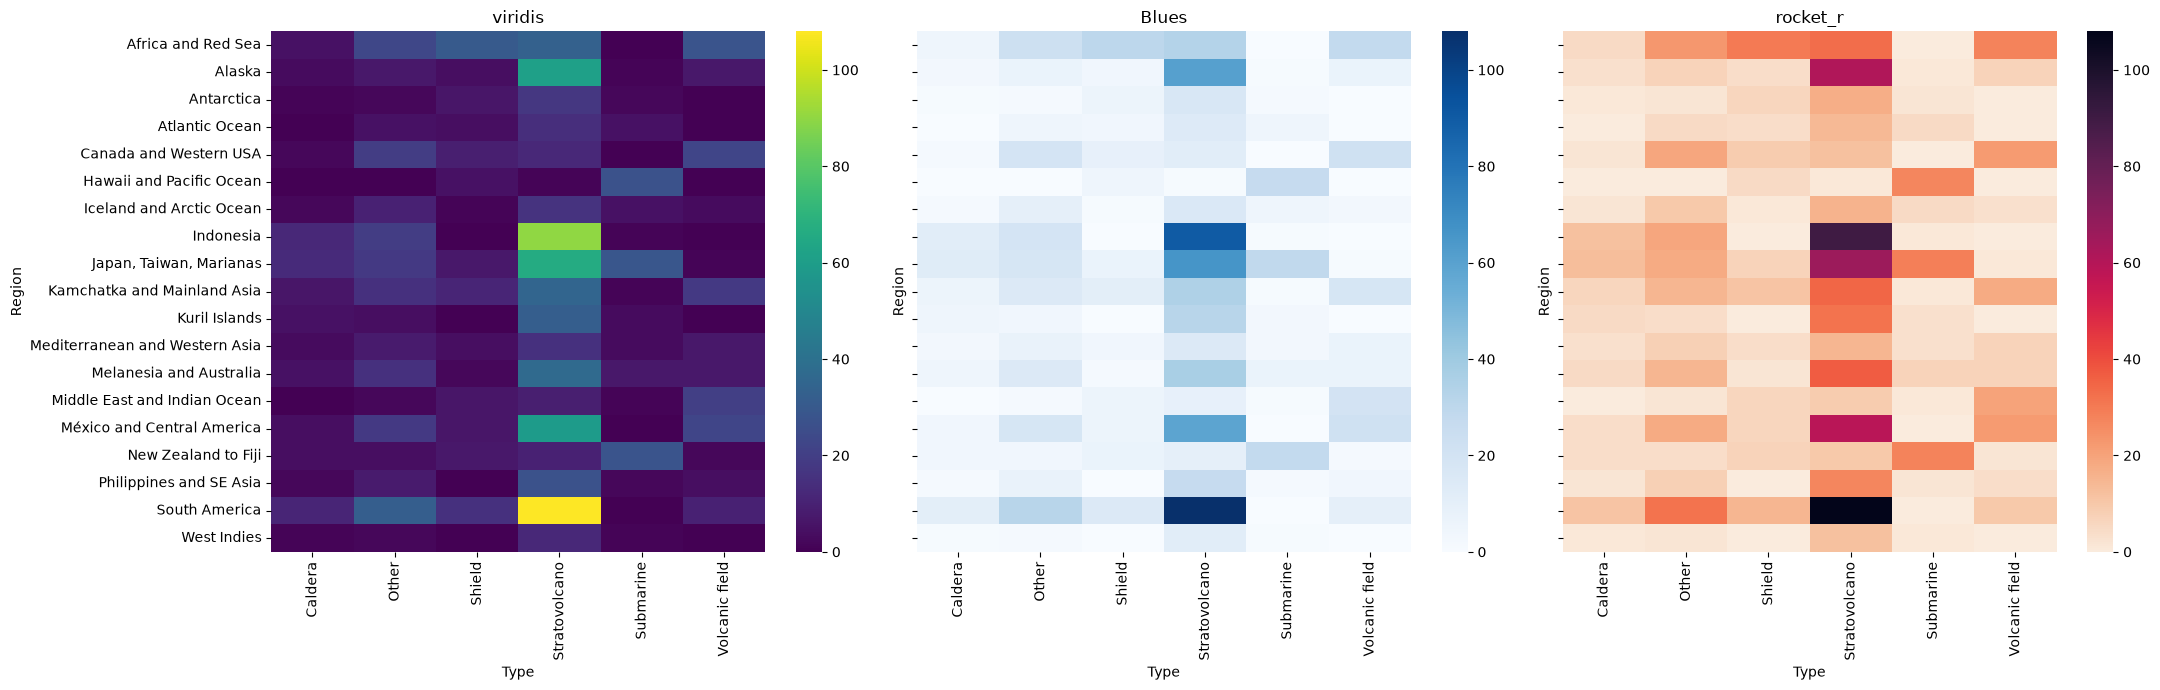

In [25]:
fig, ax = plt.subplots(1, 3, figsize=(22, 7), sharey=True)
for i, cmap in enumerate(['viridis', 'Blues', 'rocket_r']):
    sns.heatmap(counts, cmap=cmap, ax=ax[i])
    ax[i].set_title(cmap)
plt.tight_layout()
plt.show()

**Answers**:

- The `_r` suffix reverses the direction of a colormap
  - So, `rocket_r` runs from the light end (low values) to the dark end (high values) — the opposite of `rocket`.
- Answers on which is clearest will vary.
  - `rocket_r` and `viridis` are both **perceptually uniform**
    - i.e. means equal steps in data value produce equal steps in perceived brightness.
  - `Blues` is uniform, too, but may make the sparse cells harder to distinguish from the white background.

### Task 3

Draw the `counts` heatmap twice side by side:

- Left panel: default color scale.
- Right panel: `vmin=0`, `vmax=30`.

With the default scale, a few dominant cells (South America and Japan/Taiwan/Marianas stratovolcanoes) compress everything else toward the dark end.

With `vmax=30`, what patterns in the less common types become visible?

What is the trade-off of fixing `vmax` below the true maximum?

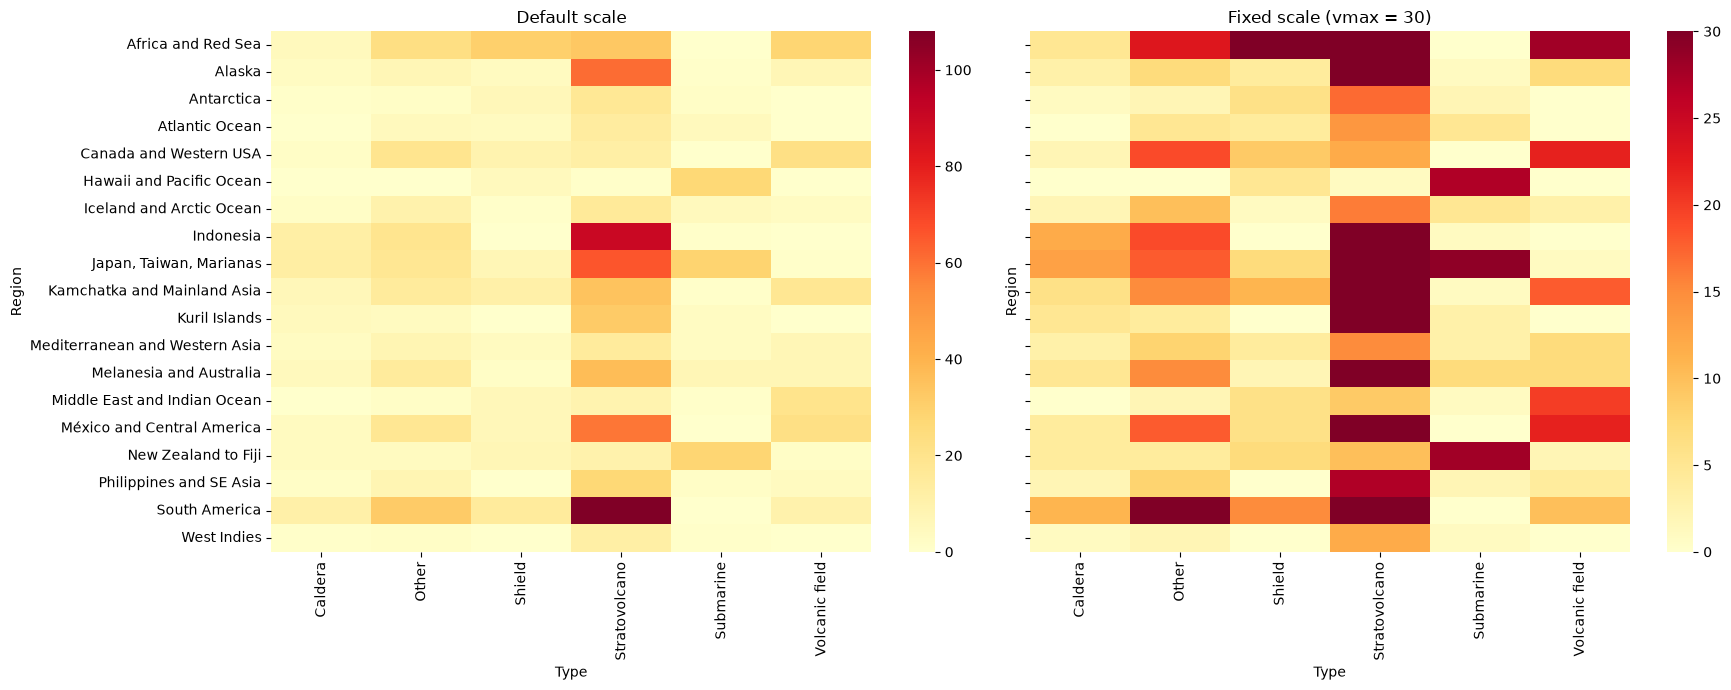

In [26]:
fig, ax = plt.subplots(1, 2, figsize=(18, 7), sharey=True)

sns.heatmap(counts, cmap='YlOrRd', ax=ax[0])
ax[0].set_title('Default scale')

sns.heatmap(counts, cmap='YlOrRd', vmin=0, vmax=30, ax=ax[1])
ax[1].set_title('Fixed scale (vmax = 30)')

plt.tight_layout()
plt.show()

**Answers**:

- With `vmax=30`, the dominant stratovolcano cells are **clipped** to the maximum color.

  - **But** the variation in shields, volcanic fields, and calderas across regions becomes readable.

  - For example, Africa/Red Sea's volcanic fields, Alaska's shields, and Hawaii's submarine presence are now visible as meaningful brightness differences rather than near-zero noise.

- The trade-off:

  - by clipping the dominant cells, we lose the ability to compare them against each other — a cell at 140 looks the same as one at 31.

  - Fixing `vmax` below the data maximum is the more honest technique, but you need to acknowledge it in a caption or annotation.

### Task 4

Create a second pivot table of **mean elevation** with `Region` as rows and `Type` as columns.

Use `aggfunc='mean'` (no `fill_value` — leave missing combinations as NaN).

Store it as `elevations`.

Draw it twice side by side:

- Left panel: `cmap='viridis'` (sequential).
- Right panel: `cmap='RdBu_r'`, `center=0` (diverging, centered at sea level).

What is the significance of zero in this dataset?

Why is a diverging colormap more meaningful for elevation than for the counts in Tasks 1–3?

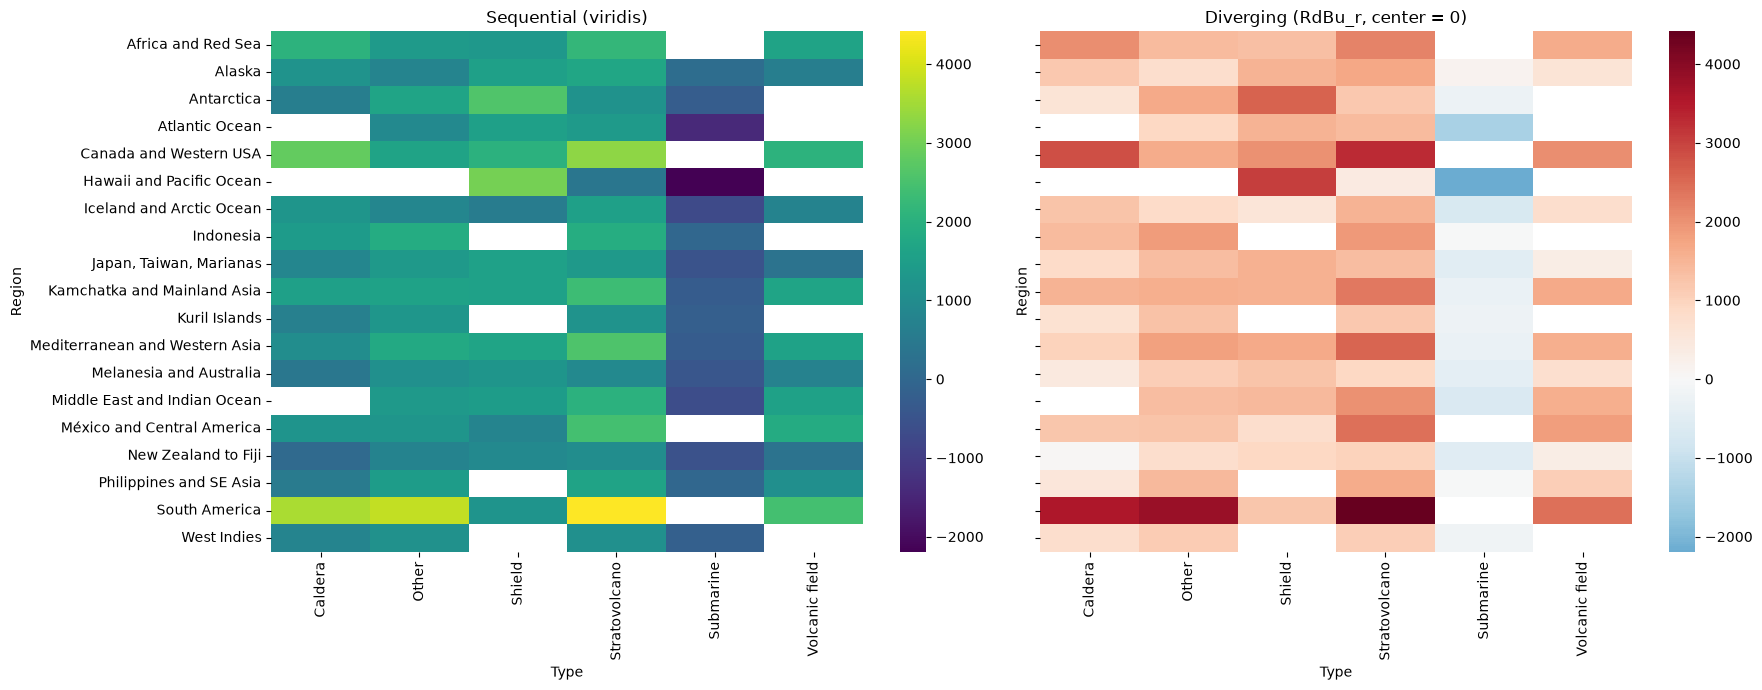

In [27]:
elevations = pd.pivot_table(
    volcanoes, 
    index='Region', 
    columns='Type',
    values='Elevation', 
    aggfunc='mean'
)

fig, axes = plt.subplots(1, 2, figsize=(18, 7), sharey=True)

sns.heatmap(elevations, cmap='viridis', ax=axes[0])
axes[0].set_title('Sequential (viridis)')

sns.heatmap(elevations, cmap='RdBu_r', center=0, ax=axes[1])
axes[1].set_title('Diverging (RdBu_r, center = 0)')

plt.tight_layout()
plt.show()

**Answers**:

- Zero is sea level — a physically meaningful boundary separating terrestrial volcanoes (positive elevation) from submarine ones (negative).

  - It is not just a statistical artifact; it divides the data into two qualitatively different categories.

- A diverging colormap centered at zero makes that boundary visible:

  - warm colors show above-sea-level summits, cool colors show underwater summits, and white sits at sea level.

  - With `viridis`, a submarine volcano at $−500$ m and a coastal one at $500$ m look like similar values near the low end of the scale — the crossing of zero is invisible.

- The counts in Tasks 1–3 have no such boundary:

  - Zero just means absent, not a qualitative change in kind.
  - A sequential colormap was correct there.

### Task 5

Draw the `elevations` heatmap twice side by side: once with `cmap='jet'` and once with `cmap='RdBu_r'` and `center=0`.

Where does `jet` create a visual boundary that does not correspond to anything real in the data?

Where does `jet` hide a real boundary that `RdBu_r` makes visible?

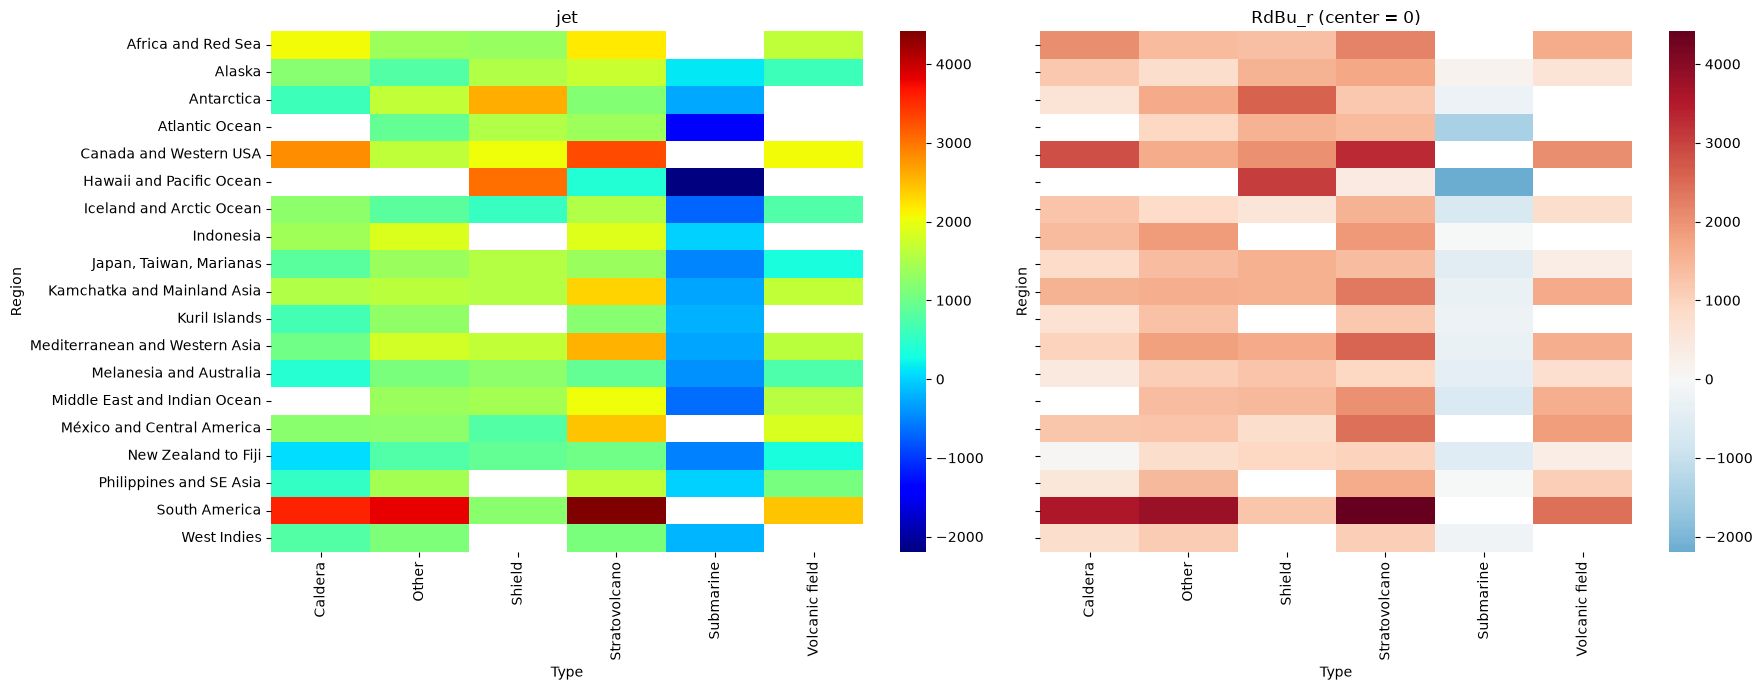

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7), sharey=True)

sns.heatmap(elevations, cmap='jet', ax=axes[0])
axes[0].set_title('jet')

sns.heatmap(elevations, cmap='RdBu_r', center=0, ax=axes[1])
axes[1].set_title('RdBu_r (center = 0)')

plt.tight_layout()
plt.show()

**Answers**:

- `jet` cycles through multiple hues — red, yellow, green, cyan, blue — at roughly equal intervals across the data range.

  - Each hue transition creates a sharp color edge that looks like a real boundary, even where the data changes gradually.

  - In the elevation data, the yellow-to-green boundary appears somewhere in the mid-range positive elevations (roughly 1000–2000 m) and signals nothing geologically meaningful.

- Meanwhile, the real boundary, sea level ($0$ m), sits wherever the colormap happens to place that value.

  - In `jet` it falls in the middle of a gradual blue-to-cyan transition that is easy to overlook.

  - `RdBu_r` places the neutral white at exactly `center=0`, making sea level unmistakable.

Additionally, `jet` is inaccessible to red-green colorblind viewers, who cannot distinguish its two ends.

### Task 6

Filter `counts` down to the **six busiest regions** (highest total volcano count).

Hint: `counts.sum(axis=1).sort_values(ascending=False).head(6).index`

Draw the filtered heatmap with `annot=True`, `fmt='d'`, and `linewidths=0.5`.

Does annotation add value on a 6-row matrix?

What would happen if you tried to annotate the full 19-row `counts` matrix instead?

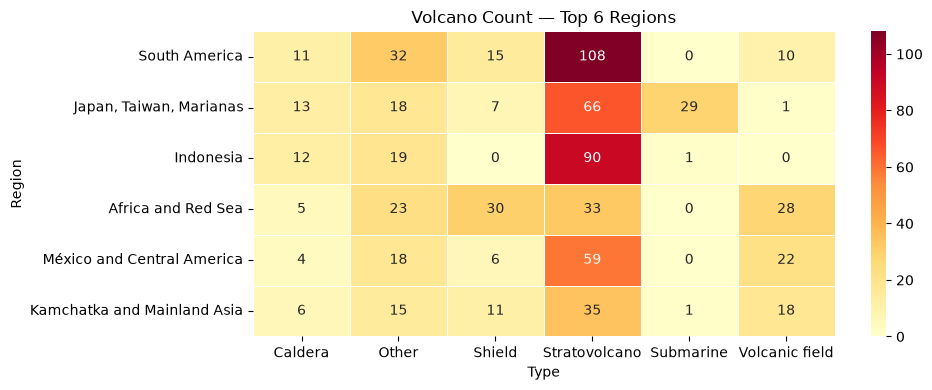

In [30]:
top6 = counts.sum(axis=1).sort_values(ascending=False).head(6).index
counts_top6 = counts.loc[top6]

plt.figure(figsize=(10, 4))
sns.heatmap(counts_top6, annot=True, fmt='d', linewidths=0.5, cmap='YlOrRd')
plt.title('Volcano Count — Top 6 Regions')
plt.tight_layout()
plt.show()

**Answers**:

- Yes — annotation adds real value on a 6×6 matrix.

  - Color tells us which cells are relatively large or small, but it cannot distinguish 28 from 32 or 1 from 5.

  - Exact numbers let you make precise comparisons: for example, South America has 140 stratovolcanoes versus Japan's 95, a ratio that is hard to read from color alone.

- On the full 19-row matrix, annotation would crowd the cells

  - with 114 numbers packed into small tiles, the text becomes too small to read and the labels fight with the color for attention.

  - Annotation works best when the matrix is small enough that each cell has room to hold a legible number.